In [4]:
from pathlib import Path
import pandas as pd

RESULTS_PATH = Path("../data/processed/forecast_test_results.csv")

print("Looking for:", RESULTS_PATH.resolve())
print("File exists:", RESULTS_PATH.exists())

results = pd.read_csv(
    RESULTS_PATH,
    parse_dates=["Datetime"]
)

print("Results loaded successfully!")
print("Shape:", results.shape)
display(results.head())

Looking for: C:\Users\ASUS\GridSense\data\processed\forecast_test_results.csv
File exists: True
Results loaded successfully!
Shape: (29073, 4)


,Datetime,PJME_MW,Forecast,Baseline_Prediction
0,2015-04-09 13:00:00,32809.0,32208.610418,33148.0
1,2015-04-09 14:00:00,32613.0,31887.601382,32809.0
2,2015-04-09 15:00:00,32204.0,31740.474369,32613.0
3,2015-04-09 16:00:00,32049.0,31487.500272,32204.0
4,2015-04-09 17:00:00,32209.0,31268.330642,32049.0


In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

RESULTS_PATH = Path("../data/processed/forecast_test_results.csv")
results = pd.read_csv(RESULTS_PATH, parse_dates=["Datetime"])

results = results.dropna(
    subset=["PJME_MW", "Baseline_Prediction", "Forecast"]
)

baseline_mae = mean_absolute_error(
    results["PJME_MW"], results["Baseline_Prediction"]
)
baseline_rmse = np.sqrt(mean_squared_error(
    results["PJME_MW"], results["Baseline_Prediction"]
))

model_mae = mean_absolute_error(
    results["PJME_MW"], results["Forecast"]
)
model_rmse = np.sqrt(mean_squared_error(
    results["PJME_MW"], results["Forecast"]
))

evaluation = pd.DataFrame({
    "Model": ["Persistence Baseline", "Random Forest"],
    "MAE (MW)": [baseline_mae, model_mae],
    "RMSE (MW)": [baseline_rmse, model_rmse]
})

display(evaluation)

print(f"MAE improvement: {(baseline_mae - model_mae) / baseline_mae * 100:.2f}%")
print(f"RMSE improvement: {(baseline_rmse - model_rmse) / baseline_rmse * 100:.2f}%")

,Model,MAE (MW),RMSE (MW)
0,Persistence Baseline,1069.75104,1373.620360
1,Random Forest,3095.94152,3976.892676


MAE improvement: -189.41%
RMSE improvement: -189.52%


In [6]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

results = pd.read_csv(
    Path("../data/processed/forecast_test_results_v2.csv"),
    parse_dates=["Datetime"]
).dropna(
    subset=["PJME_MW", "Forecast", "Baseline_Prediction"]
)

comparison = []

for name, column in [
    ("Persistence Baseline", "Baseline_Prediction"),
    ("Random Forest V2", "Forecast")
]:
    comparison.append({
        "Model": name,
        "MAE (MW)": mean_absolute_error(
            results["PJME_MW"], results[column]
        ),
        "RMSE (MW)": np.sqrt(mean_squared_error(
            results["PJME_MW"], results[column]
        ))
    })

display(pd.DataFrame(comparison))

,Model,MAE (MW),RMSE (MW)
0,Persistence Baseline,1070.151693,1373.962678
1,Random Forest V2,331.355278,458.252702


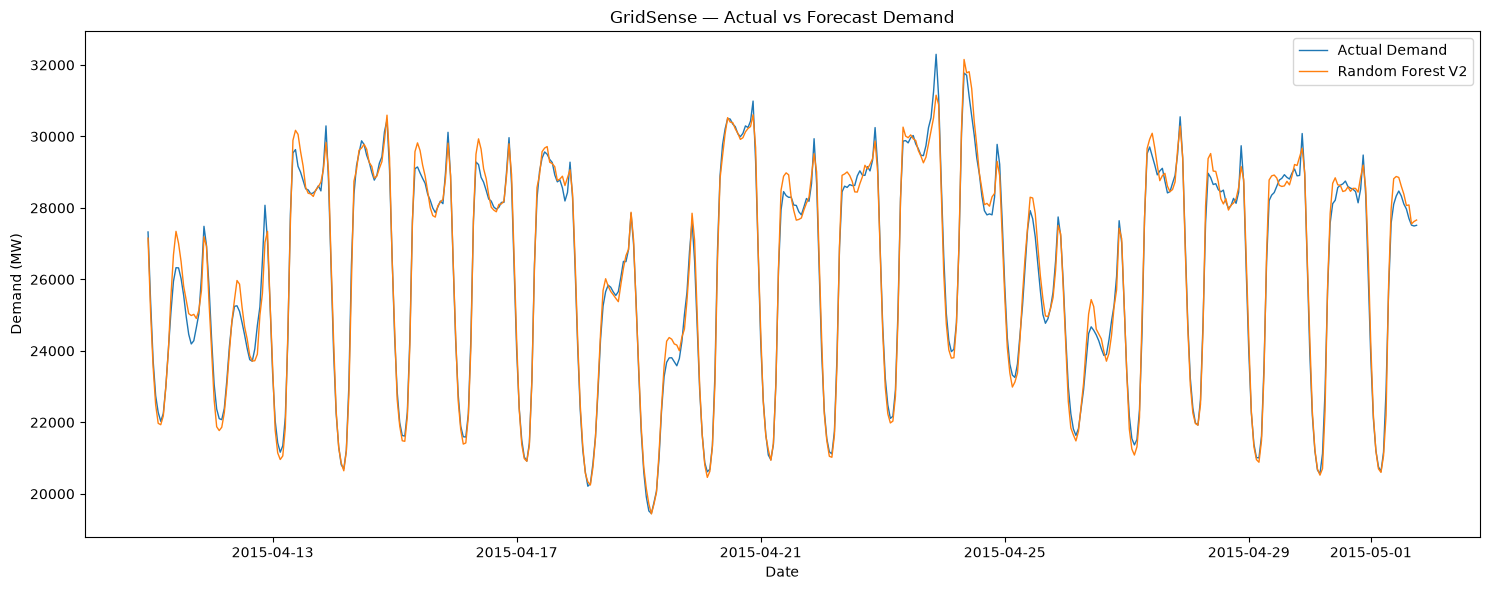

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    results["Datetime"].iloc[:500],
    results["PJME_MW"].iloc[:500],
    label="Actual Demand",
    linewidth=1
)

plt.plot(
    results["Datetime"].iloc[:500],
    results["Forecast"].iloc[:500],
    label="Random Forest V2",
    linewidth=1
)

plt.title("GridSense — Actual vs Forecast Demand")
plt.xlabel("Date")
plt.ylabel("Demand (MW)")
plt.legend()
plt.tight_layout()
plt.show()

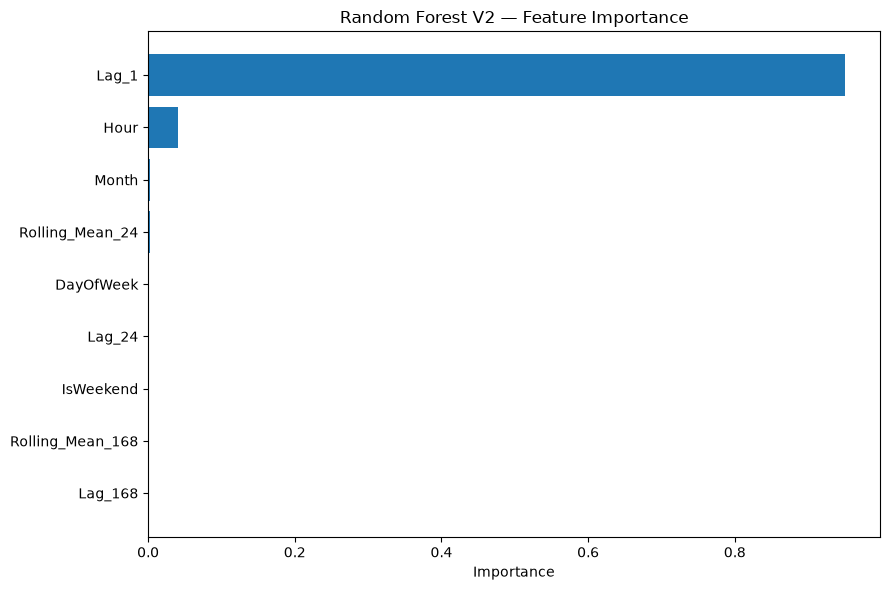

,Feature,Importance
4,Lag_1,0.950455
0,Hour,0.040984
2,Month,0.002596
7,Rolling_Mean_24,0.002517
1,DayOfWeek,0.000990
5,Lag_24,0.000883
3,IsWeekend,0.000655
8,Rolling_Mean_168,0.000496
6,Lag_168,0.000423


In [8]:
import joblib
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

model_path = Path(
    "../data/processed/random_forest_forecaster_v2.joblib"
)

forecast_model = joblib.load(model_path)

features = [
    "Hour", "DayOfWeek", "Month", "IsWeekend",
    "Lag_1", "Lag_24", "Lag_168",
    "Rolling_Mean_24", "Rolling_Mean_168"
]

importance = pd.DataFrame({
    "Feature": features,
    "Importance": forecast_model.feature_importances_
}).sort_values("Importance", ascending=True)

plt.figure(figsize=(9, 6))
plt.barh(importance["Feature"], importance["Importance"])
plt.title("Random Forest V2 — Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

display(importance.sort_values("Importance", ascending=False))

In [ ]:
3